In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(7)

In [4]:
dates = pd.date_range("2025-01-01","2025-12-31",freq="D")
n = len(dates)
print("Total Days:",n)

Total Days: 365


In [5]:
products = rng.choice(["Laptop","Phone","Tablet","Headphones"],n,p=[0.2, 0.4, 0.15, 0.25])
regions = rng.choice(["North","South","East","West"],n)

In [7]:
base_price = {
    "Laptop": 55000,
    "Phone": 25000,
    "Tablet": 30000,
    "Headphones": 3000
}
units = rng.poisson(8, n) + 1

In [8]:
season = 1 + 0.3 * np.sin(2 * np.pi * (dates.dayofyear - 80) / 365)
print(season)

Index([ 0.706645497548303, 0.7077698634482739, 0.7089808234445478,
       0.7102780187035436, 0.7116610648383097, 0.7131295520224283,
        0.714683045111454, 0.7163210837718572, 0.7180431826174314,
       0.7198488313531224,
       ...
       0.7002249966280949, 0.7004693736533307, 0.7008025080675533,
       0.7012243011558463, 0.7017346279318144, 0.7023333371746203,
       0.7030202514737941, 0.7037951672818041, 0.7046578549743723,
       0.7056080589185172],
      dtype='float64', length=365)


In [9]:
price = np.array([base_price[p] for p in products])
print(price)

[30000  3000  3000 25000 25000  3000 55000  3000  3000 25000 25000 25000
 25000 25000 25000 25000  3000  3000 30000  3000 25000 55000 30000 55000
 55000 25000 25000  3000 30000 25000 25000 25000 55000 55000 30000 25000
 25000 55000  3000 55000 25000  3000 25000  3000 30000 30000 55000 25000
 25000  3000 25000 25000 55000 25000 25000 55000  3000 25000  3000 25000
 30000 30000 30000 55000 25000 25000 25000 55000  3000 25000 30000 25000
  3000 30000 55000  3000  3000  3000 25000 55000 55000  3000 25000 55000
  3000 30000 25000 25000 25000 25000 55000  3000 25000 25000 25000  3000
 55000 25000 55000 55000  3000 30000 25000 25000  3000 25000 25000 30000
 25000 25000  3000  3000 55000  3000 55000  3000  3000 55000 25000  3000
 55000 30000  3000 25000 30000 25000 55000 25000 55000 25000  3000 25000
 25000 25000  3000 25000  3000 25000 25000  3000 30000 25000 25000  3000
 25000  3000 55000 25000 25000  3000 25000  3000 30000 30000 30000  3000
 25000 25000 25000 55000 25000  3000  3000 55000 30

In [10]:
sales = pd.DataFrame({"date": dates,"product": products,"region": regions,"units": units,"revenue": (units * price * season * rng.uniform(0.9,1.1,n)).round(0)})
print(sales)

          date     product region  units   revenue
0   2025-01-01      Tablet  South      7  138006.0
1   2025-01-02  Headphones   East      5   11371.0
2   2025-01-03  Headphones   West      5    9772.0
3   2025-01-04       Phone  South     11  201554.0
4   2025-01-05       Phone   West      9  166651.0
..         ...         ...    ...    ...       ...
360 2025-12-27       Phone  North      7  121418.0
361 2025-12-28       Phone  South      6   96306.0
362 2025-12-29       Phone  North      7  119729.0
363 2025-12-30       Phone  South     11  190236.0
364 2025-12-31      Tablet   West      5   95339.0

[365 rows x 5 columns]


In [11]:
# head 
print(sales.head())

        date     product region  units   revenue
0 2025-01-01      Tablet  South      7  138006.0
1 2025-01-02  Headphones   East      5   11371.0
2 2025-01-03  Headphones   West      5    9772.0
3 2025-01-04       Phone  South     11  201554.0
4 2025-01-05       Phone   West      9  166651.0


In [12]:
# shape
print(sales.shape)

(365, 5)


In [15]:
# info
print(sales.info())

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   date     365 non-null    datetime64[us]
 1   product  365 non-null    str           
 2   region   365 non-null    str           
 3   units    365 non-null    int64         
 4   revenue  365 non-null    float64       
 5   month    365 non-null    str           
dtypes: datetime64[us](1), float64(1), int64(1), str(3)
memory usage: 23.4 KB
None


#### add new column date wise

In [19]:
# add new column :- month
sales["month"] = sales["date"].dt.month_name()

In [20]:
# add new column :- month_num
sales["month_num"] = sales["date"].dt.month

In [21]:
# add new column :- weekly
sales["weekday"] = sales["date"].dt.day_name()

In [22]:
print(sales.head())

        date     product region  units   revenue    month  month_num  \
0 2025-01-01      Tablet  South      7  138006.0  January          1   
1 2025-01-02  Headphones   East      5   11371.0  January          1   
2 2025-01-03  Headphones   West      5    9772.0  January          1   
3 2025-01-04       Phone  South     11  201554.0  January          1   
4 2025-01-05       Phone   West      9  166651.0  January          1   

     weekday  
0  Wednesday  
1   Thursday  
2     Friday  
3   Saturday  
4     Sunday  


In [24]:
# monthly sales analysis
monthly = sales.groupby("month_num")["revenue"].sum()
print(monthly)

month_num
1      4554588.0
2      5062647.0
3      7480844.0
4      8022915.0
5      8557394.0
6      9614327.0
7     10430098.0
8      8813035.0
9      8231465.0
10     5766018.0
11     5367778.0
12     5728909.0
Name: revenue, dtype: float64


In [27]:
print("Best Month:- ",monthly.idxmax())

Best Month:-  7


In [28]:
print("Worst Month:- ",monthly.idxmin())

Worst Month:-  1


In [29]:
# Product wise analysis
product_analysis = sales.groupby("product")["revenue"].agg(["sum","mean","count"]).round(0)
print(product_analysis)

                   sum      mean  count
product                                
Headphones   2668672.0   27231.0     98
Laptop      39949986.0  499375.0     80
Phone       30423031.0  225356.0    135
Tablet      14588329.0  280545.0     52


## Pivot table

In [30]:
pivot = sales.pivot_table(index="product",columns="region",values="revenue",aggfunc="sum")
print(pivot.round(0))

region            East       North      South       West
product                                                 
Headphones    554896.0    581434.0   652032.0   880310.0
Laptop      11549568.0  12948272.0  8624298.0  6827848.0
Phone        5779448.0   5329163.0  9819139.0  9495281.0
Tablet       3260380.0   2627729.0  4708367.0  3991853.0


In [32]:
# Daily based revenue calculate 
daily = sales.groupby("date")["revenue"].sum()
print(daily.head())

date
2025-01-01    138006.0
2025-01-02     11371.0
2025-01-03      9772.0
2025-01-04    201554.0
2025-01-05    166651.0
Name: revenue, dtype: float64


In [33]:
# seven-days rolling average
rolling = daily.rolling(7).mean()
print(rolling.head(10))

date
2025-01-01              NaN
2025-01-02              NaN
2025-01-03              NaN
2025-01-04              NaN
2025-01-05              NaN
2025-01-06              NaN
2025-01-07    130314.857143
2025-01-08    113268.714286
2025-01-09    114280.428571
2025-01-10    127568.285714
Name: revenue, dtype: float64


## ***Line Plot***

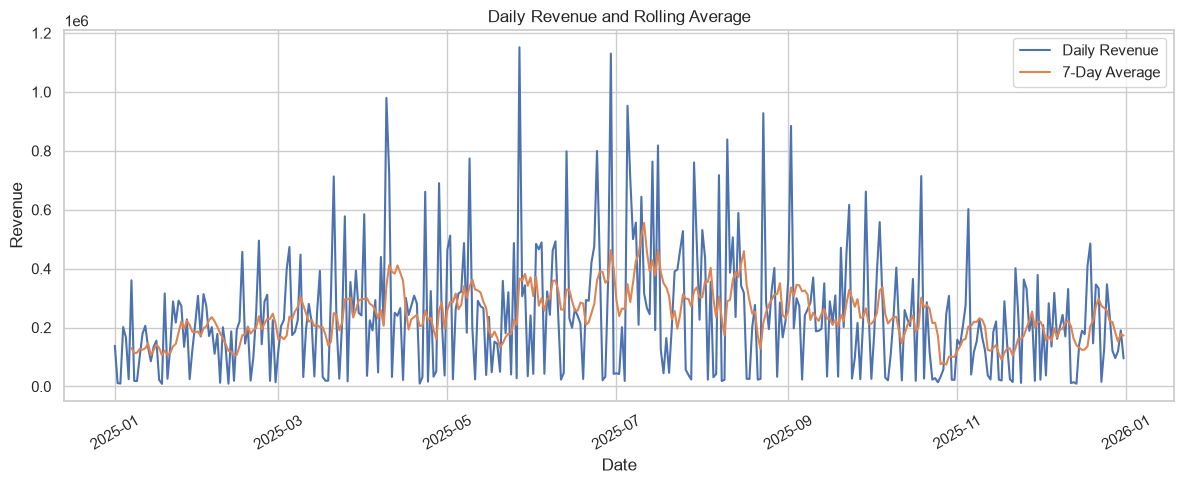

In [34]:
plt.figure(figsize=(12,5))
plt.plot(daily.index,daily.values,label="Daily Revenue")
plt.plot(rolling.index,rolling.values,label="7-Day Average")
plt.title("Daily Revenue and Rolling Average")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## ***Monthly Bar Chart***

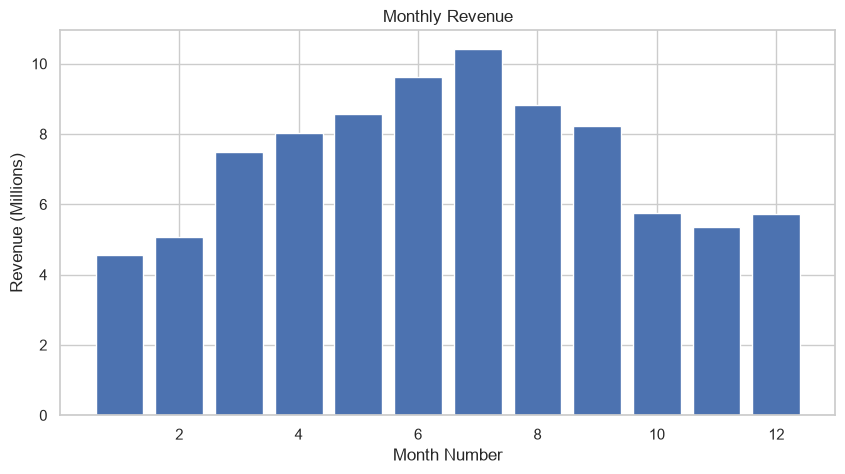

In [35]:
plt.figure(figsize=(10,5))
plt.bar(monthly.index,monthly.values / 1000000)
plt.title("Monthly Revenue")
plt.xlabel("Month Number")
plt.ylabel("Revenue (Millions)")
plt.show()

## ***Histogram PLot***

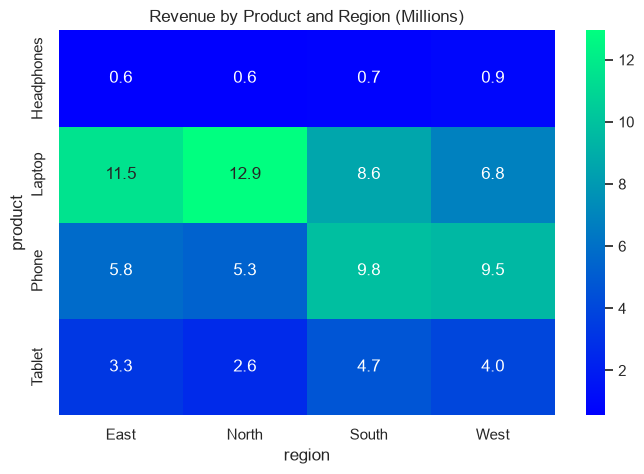

In [37]:
plt.figure(figsize=(8,5))
sns.heatmap(pivot / 1000000,annot=True,fmt=".1f",cmap="winter")
plt.title("Revenue by Product and Region (Millions)")
plt.show()

## ***Weekly Box Plot***

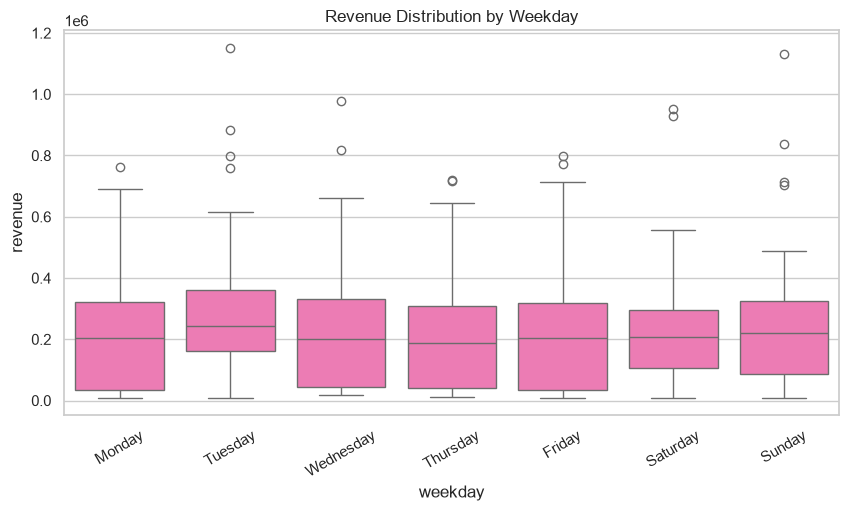

In [49]:
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
plt.figure(figsize=(10,5))
sns.boxplot(data=sales,x="weekday",y="revenue",order=order,color="hotpink")
plt.title("Revenue Distribution by Weekday")
plt.xticks(rotation=30)
plt.show()

## ***Complete Sales Dashboard***

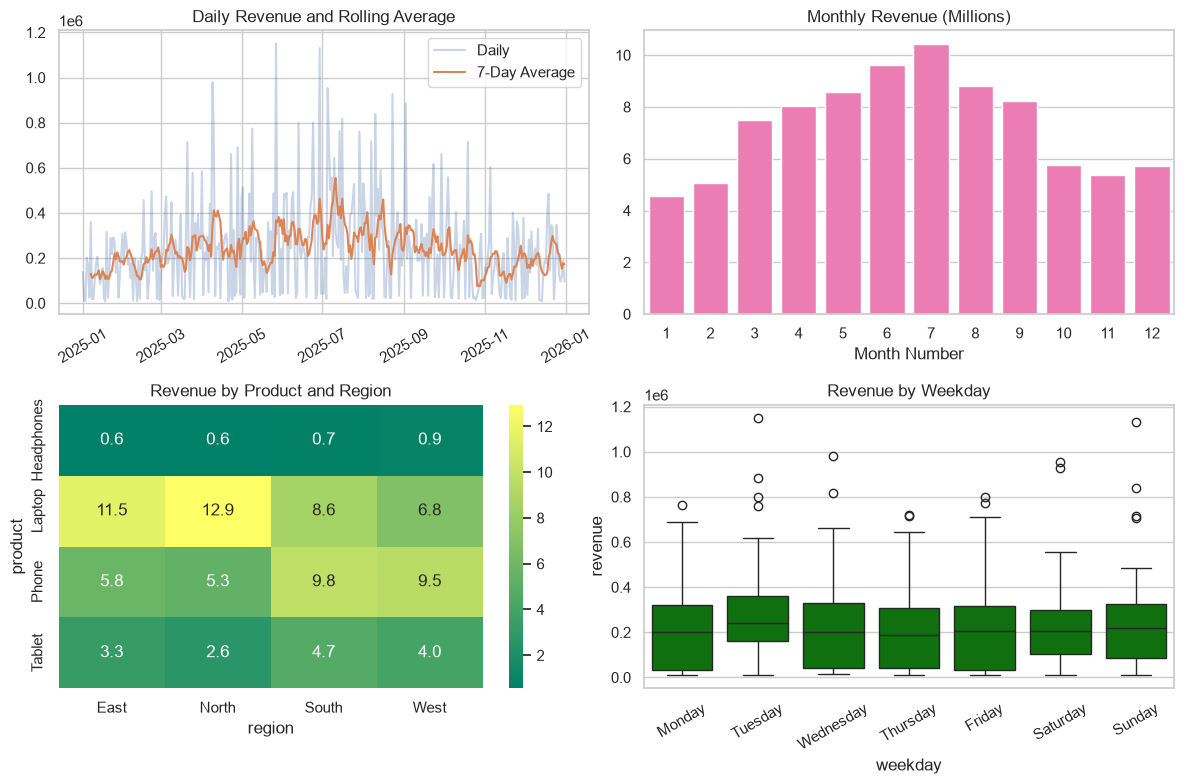

In [53]:
fig, axes = plt.subplots(2,2,figsize=(12,8))
axes[0,0].plot(daily.index,daily.values,alpha=0.3,label="Daily")
axes[0,0].plot(rolling.index,rolling.values,label="7-Day Average")
axes[0,0].set_title("Daily Revenue and Rolling Average")
axes[0,0].legend()
axes[0,0].tick_params(axis="x",rotation=30)
sns.barplot(x=monthly.index,y=monthly.values / 1000000,ax=axes[0,1],color="hotpink")
axes[0,1].set_title("Monthly Revenue (Millions)")
axes[0,1].set_xlabel("Month Number")
sns.heatmap(pivot / 1000000,annot=True,fmt=".1f",ax=axes[1,0],cmap="summer")
axes[1,0].set_title("Revenue by Product and Region")
sns.boxplot(data=sales,x="weekday",y="revenue",order=order,ax=axes[1,1],color="green")
axes[1,1].set_title("Revenue by Weekday")
axes[1,1].tick_params(axis="x",rotation=30)
plt.tight_layout()
plt.savefig("Yearly Sales Analysis.png",dpi=150)
plt.show()

In [51]:
sales.to_csv("yearly_sales_analysis.csv",index=False)

In [52]:
pivot.to_csv("product_region_revenue.csv")

In [54]:
import os
print(os.getcwd())

C:\Users\Ks\Revision_Python\DSML_7pm\Task
